# pyDDRL

> Distributional Deterministic Reinforcement Learning

This file will become your README and also the index of your documentation.

## Developer Guide

If you are new to using `nbdev` here are some useful pointers to get you started.

### Install pyDDRL in Development mode

```sh
# make sure pyDDRL package is installed in development mode
$ pip install -e .

# make changes under nbs/ directory
# ...

# compile to have changes apply to pyDDRL
$ nbdev_prepare
```

## Usage

### Installation

Install latest from the GitHub [repository][repo]:

```sh
$ pip install git+https://github.com/clembergerot/pyDDRL.git
```

or from [conda][conda]

```sh
$ conda install -c clembergerot pyDDRL
```

or from [pypi][pypi]


```sh
$ pip install pyDDRL
```


[repo]: https://github.com/clembergerot/pyDDRL
[docs]: https://clembergerot.github.io/pyDDRL/
[pypi]: https://pypi.org/project/pyDDRL/
[conda]: https://anaconda.org/clembergerot/pyDDRL

### Documentation

Documentation can be found hosted on this GitHub [repository][repo]'s [pages][docs]. Additionally you can find package manager specific guidelines on [conda][conda] and [pypi][pypi] respectively.

[repo]: https://github.com/clembergerot/pyDDRL
[docs]: https://clembergerot.github.io/pyDDRL/
[pypi]: https://pypi.org/project/pyDDRL/
[conda]: https://anaconda.org/clembergerot/pyDDRL

## How to use

Plot a simple flowplot:

Text(0.5, 0, 'prob. safe in prosp. state')

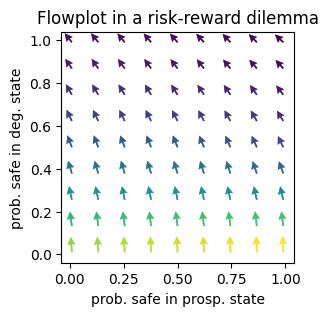

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Environment
from pyDDRL.Environments.RiskRewardDilemma import RiskRewardDilemma

# Agent
from pyDDRL.Agents.DDRLBase import DDRLBase
from pyDDRL.Agents.DDRLActorCritic import DDRLActorCritic

# Utilities
from pyCRLD.Utils.Helpers import *
from pyCRLD.Utils import FlowPlot as fp
from pyDDRL.Utils.PlottingTools import *

# Define environment
env = RiskRewardDilemma(pc=0.1, pr=0.2, rc=0.5, rr=1, rd=0)

# Define agent
aei = DDRLActorCritic(env, nr_reward_bins=29, discretization_sigma=0.05, 
                      learning_rates=0.1, discount_factors=0.9, 
                      Rmin=0, Rmax=1,
                      method="mean", use_prefactor=True)


# Plot
x = ([0], [0], [0])  # prosperous state
y = ([0], [1], [0])  # degraded state

fig, ax = plt.subplots(1, 1, figsize=(3,3))
fp.plot_strategy_flow(aei, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), 
                      NrRandom=16, axes=ax)
ax.set_title("Flowplot in a risk-reward dilemma")
ax.set_ylabel("prob. safe in deg. state")
ax.set_xlabel("prob. safe in prosp. state")